# Soul mates with Bayes, on simulated data

Everyone has one soul mate, drawn at random from the M people born within 5 years of them. You find them only if you lock eyes and recognize each other. This notebook estimates how many new people you meet per day, turns that into lifetime eye contacts, and then into the chance of finding your soul mate. The data is simulated with known true values, so we can check the model.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from soulmates.model import age_band, build_model, p_find
from soulmates.simulate import simulate_diaries

# Made up true values: mean new contacts per day for each 5 year band, peaking at ages 20 to 24
TRUE_BAND_MEANS = [1.0, 1.5, 2.0, 3.0, 4.0, 3.5, 3.0, 2.5, 2.5, 2.0, 2.0, 1.5, 1.5, 1.0, 1.0, 1.0, 1.0]
TRUE_ALPHA = 2.0
df = simulate_diaries(3000, TRUE_BAND_MEANS, TRUE_ALPHA, seed=1)
df.head()

,age,new_contacts
0,40,3
1,43,0
2,64,2
3,80,0
4,2,1


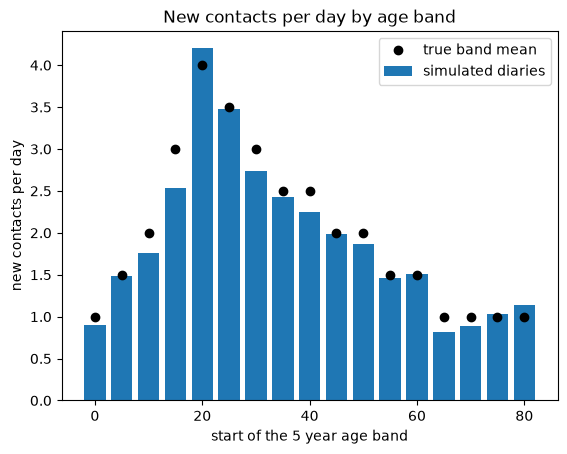

In [2]:
observed = df.groupby(age_band(df["age"]))["new_contacts"].mean()
fig, ax = plt.subplots()
ax.bar(observed.index * 5, observed.values, width=4, label="simulated diaries")
ax.plot(np.arange(17) * 5, TRUE_BAND_MEANS, "ko", label="true band mean")
ax.set(xlabel="start of the 5 year age band", ylabel="new contacts per day", title="New contacts per day by age band")
ax.legend();

## Prior predictive check

Before fitting, we draw fake diaries from the priors alone. They should cover the simulated diaries without putting much weight on absurd days.

Sampling: [alpha, mu_pop, new_contacts, p_eye, p_recog, sigma_band, z]


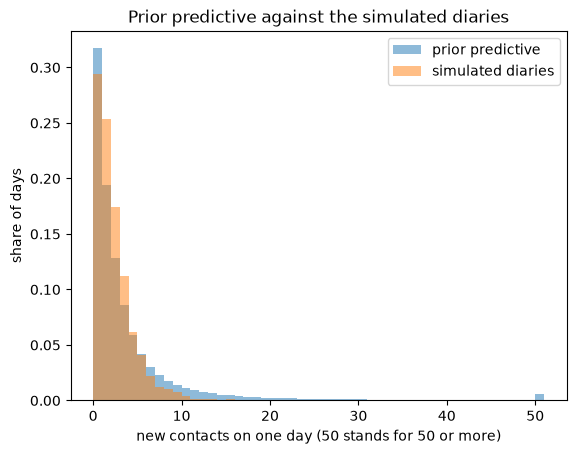

In [3]:
model = build_model(df)
with model:
    prior = pm.sample_prior_predictive(random_seed=3)
prior_counts = prior.prior_predictive["new_contacts"].values.ravel()
bins = np.arange(52)
fig, ax = plt.subplots()
ax.hist(np.minimum(prior_counts, 50), bins=bins, density=True, alpha=0.5, label="prior predictive")
ax.hist(np.minimum(df["new_contacts"], 50), bins=bins, density=True, alpha=0.5, label="simulated diaries")
ax.set(xlabel="new contacts on one day (50 stands for 50 or more)", ylabel="share of days", title="Prior predictive against the simulated diaries")
ax.legend();

## Fit and recovery

The posterior band means should sit close to the true values.

In [4]:
with model:
    idata = pm.sample(random_seed=2)
az.summary(idata, var_names=["mu_pop", "sigma_band", "alpha", "lifetime_new"])

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_pop, sigma_band, z, alpha, p_eye, p_recog]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 10 seconds.


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_pop,0.54,0.126,0.33,0.74,552,818,1.00,0.0054,0.003
sigma_band,0.5,0.094,0.38,0.66,814,1092,1.00,0.0032,0.0029
alpha,2.159,0.134,2,2.4,3232,2826,1.00,0.0024,0.0021
lifetime_new,3.94e+04,9.54e+02,38000,41000,4315,3567,1.00,15,13


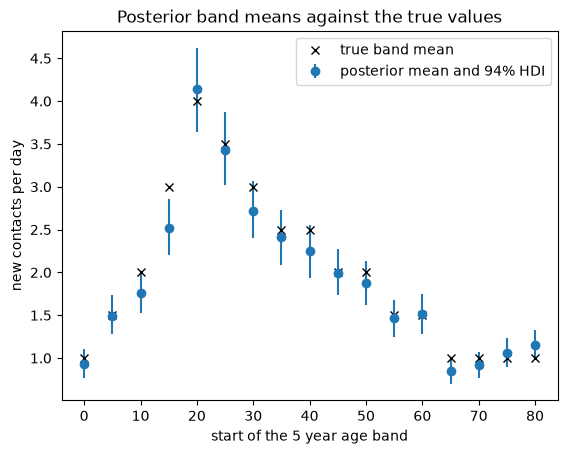

In [5]:
hdi = az.hdi(idata, var_names=["band_mean"], prob=0.94)["band_mean"].values
mean = idata.posterior["band_mean"].mean(("chain", "draw")).values
ages = np.arange(17) * 5
fig, ax = plt.subplots()
ax.errorbar(ages, mean, yerr=[mean - hdi[:, 0], hdi[:, 1] - mean], fmt="o", label="posterior mean and 94% HDI")
ax.plot(ages, TRUE_BAND_MEANS, "kx", label="true band mean")
ax.set(xlabel="start of the 5 year age band", ylabel="new contacts per day", title="Posterior band means against the true values")
ax.legend();

## The chance of finding your soul mate

P_find = 1 − (1 − p_recog / M) ^ eye_contacts. M is a placeholder here until the UN World Population Prospects cohort sizes are in.

P_find mean 9.84e-05, 94% interval 1.14e-05 to 2.43e-04


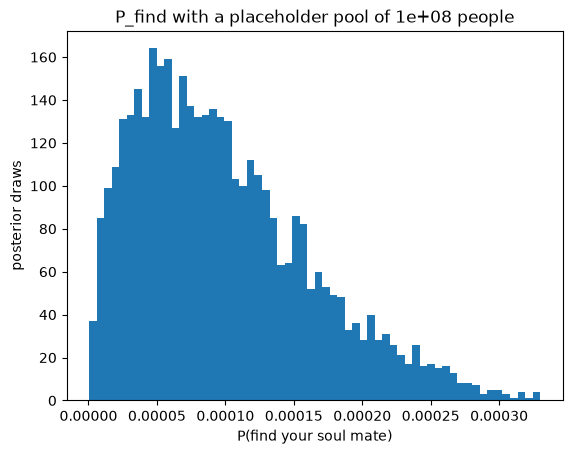

In [6]:
POOL_SIZE = 1e8  # PLACEHOLDER until the UN WPP cohort sizes arrive
pf = p_find(idata, POOL_SIZE).values.ravel()
fig, ax = plt.subplots()
ax.hist(pf, bins=60)
ax.set(xlabel="P(find your soul mate)", ylabel="posterior draws", title=f"P_find with a placeholder pool of {POOL_SIZE:.0e} people")
print(f"P_find mean {pf.mean():.2e}, 94% interval {np.percentile(pf, 3):.2e} to {np.percentile(pf, 97):.2e}")